In [ ]:
!pip install rasterio numpy pandas matplotlib seaborn scipy scikit-learn


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio

from scipy.stats import pearsonr, linregress
from sklearn.linear_model import LinearRegression

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import rasterio
from rasterio.warp import reproject, Resampling
import pandas as pd
import numpy as np

corrected_ndvi_path = 'Delhi_NDVI_Corrected_2025.tif'
lst_path = 'Delhi_LST_April_June_2025.tif'
ndbi_path = 'Delhi_NDBI_April_June_2025.tif'

# 1. Read LST as the reference grid
with rasterio.open(lst_path) as lst_src:
    lst = lst_src.read(1, masked=True).filled(np.nan)

    reference_shape = lst_src.shape
    reference_transform = lst_src.transform
    reference_crs = lst_src.crs

# 2. Read NDBI
with rasterio.open(ndbi_path) as ndbi_src:
    ndbi = ndbi_src.read(1, masked=True).filled(np.nan)

# 3. Reproject corrected NDVI onto the exact LST grid
with rasterio.open(corrected_ndvi_path) as ndvi_src:

    source_ndvi = ndvi_src.read(1, masked=True).filled(np.nan)

    aligned_ndvi = np.full(
        reference_shape,
        np.nan,
        dtype=np.float32
    )

    reproject(
        source=source_ndvi,
        destination=aligned_ndvi,
        src_transform=ndvi_src.transform,
        src_crs=ndvi_src.crs,
        dst_transform=reference_transform,
        dst_crs=reference_crs,
        src_nodata=np.nan,
        dst_nodata=np.nan,
        resampling=Resampling.nearest
    )

# 4. Check valid pixels in each raster
print("Valid LST pixels:", np.isfinite(lst).sum())
print("Valid NDBI pixels:", np.isfinite(ndbi).sum())
print("Valid NDVI pixels:", np.isfinite(aligned_ndvi).sum())

# 5. Retain pixels valid in all three rasters
valid_mask = (
    np.isfinite(lst) &
    np.isfinite(ndbi) &
    np.isfinite(aligned_ndvi) &
    (aligned_ndvi >= -1) &
    (aligned_ndvi <= 1)
)

print("Common valid pixels:", valid_mask.sum())

# 6. Construct the dataset
final_df = pd.DataFrame({
    'NDVI': aligned_ndvi[valid_mask],
    'NDBI': ndbi[valid_mask],
    'LST': lst[valid_mask]
})

# 7. Save
final_df.to_csv('delhi_combined_data_verified.csv', index=False)

print("Final dataset shape:", final_df.shape)
display(final_df.head())

Valid LST pixels: 1913316
Valid NDBI pixels: 1913316
Valid NDVI pixels: 1913316
Common valid pixels: 1913316
Final dataset shape: (1913316, 3)


,NDVI,NDBI,LST
0,0.177868,0.038102,40.605400
1,0.145964,0.046870,40.694269
2,0.145942,0.031168,40.680596
3,0.163271,0.030480,40.639580
4,0.163271,0.030480,40.639580


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import linregress
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

df = pd.read_csv('delhi_combined_data_verified.csv')

print("Observations:", len(df))

print("\nCorrelation matrix:")
print(df[['NDVI', 'NDBI', 'LST']].corr())

for variable in ['NDVI', 'NDBI']:
    result = linregress(df[variable], df['LST'])
    print(f"\n{variable} vs LST")
    print("Correlation:", result.rvalue)
    print("Slope:", result.slope)
    print("Intercept:", result.intercept)
    print("R-squared:", result.rvalue**2)

X = sm.add_constant(df[['NDVI', 'NDBI']])
model = sm.OLS(df['LST'], X).fit()

print("\nMultiple regression:")
print(model.summary())

vif = pd.DataFrame()
vif['Variable'] = X.columns
vif['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print("\nVIF:")
print(vif)

Observations: 1913316

Correlation matrix:
          NDVI      NDBI       LST
NDVI  1.000000 -0.809099 -0.462604
NDBI -0.809099  1.000000  0.645236
LST  -0.462604  0.645236  1.000000

NDVI vs LST
Correlation: -0.4626039804707931
Slope: -10.098868542897575
Intercept: 43.66525247596
R-squared: 0.21400244274742192

NDBI vs LST
Correlation: 0.6452357574940303
Slope: 21.520641645707855
Intercept: 41.48494322037042
R-squared: 0.4163291827488951

Multiple regression:
                            OLS Regression Results                            
Dep. Variable:                    LST   R-squared:                       0.427
Model:                            OLS   Adj. R-squared:                  0.427
Method:                 Least Squares   F-statistic:                 7.116e+05
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        03:53:25   Log-Likelihood:            -4.1572e+06
No. Observations:             1913316   AIC:                 

In [ ]:
print(df.shape)
print(df.isna().sum())
print(df[['NDVI','NDBI','LST']].describe())

(1913316, 3)
NDVI    0
NDBI    0
LST     0
dtype: int64
               NDVI          NDBI           LST
count  1.913316e+06  1.913316e+06  1.913316e+06
mean   2.970591e-01 -3.808676e-02  4.066529e+01
std    1.285531e-01  8.414125e-02  2.806375e+00
min   -5.220921e-02 -4.643347e-01  2.992409e+01
25%    1.922645e-01 -9.412816e-02  3.894766e+01
50%    2.696855e-01 -2.154065e-02  4.031487e+01
75%    3.891306e-01  2.445908e-02  4.199653e+01
max    7.736373e-01  3.210394e-01  5.087313e+01


THJE FINAL CODE  BLOCK

Libraries imported successfully.

Dataset loaded successfully.
Shape: (1913316, 3)

Missing values:
NDVI    0
NDBI    0
LST     0
dtype: int64

Final observations: 1913316

Variable ranges:
               NDVI          NDBI           LST
count  1.913316e+06  1.913316e+06  1.913316e+06
mean   2.970591e-01 -3.808676e-02  4.066529e+01
std    1.285531e-01  8.414125e-02  2.806375e+00
min   -5.220921e-02 -4.643347e-01  2.992409e+01
25%    1.922645e-01 -9.412816e-02  3.894766e+01
50%    2.696855e-01 -2.154065e-02  4.031487e+01
75%    3.891306e-01  2.445908e-02  4.199653e+01
max    7.736373e-01  3.210394e-01  5.087313e+01

DESCRIPTIVE STATISTICS
          count       mean       std        min        25%        50%  \
NDVI  1913316.0   0.297059  0.128553  -0.052209   0.192264   0.269686   
NDBI  1913316.0  -0.038087  0.084141  -0.464335  -0.094128  -0.021541   
LST   1913316.0  40.665292  2.806375  29.924088  38.947660  40.314868   

            75%        max  
NDVI   0.389131   0.773637  
NDB

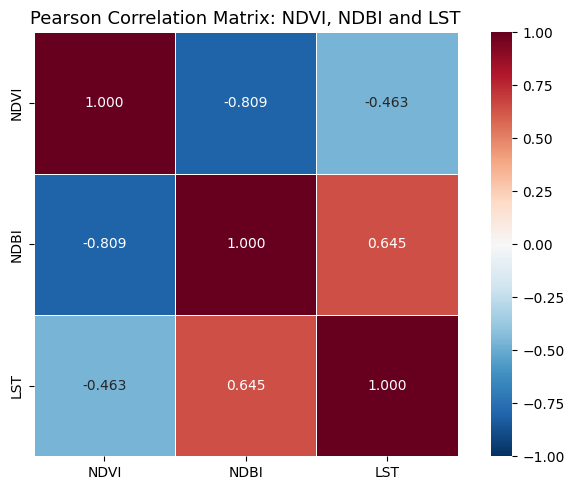


NDVI vs LST
Pearson correlation (r): -0.4626
Slope: -10.0989
Intercept: 43.6653
R-squared: 0.2140
P-value: 0.0000e+00


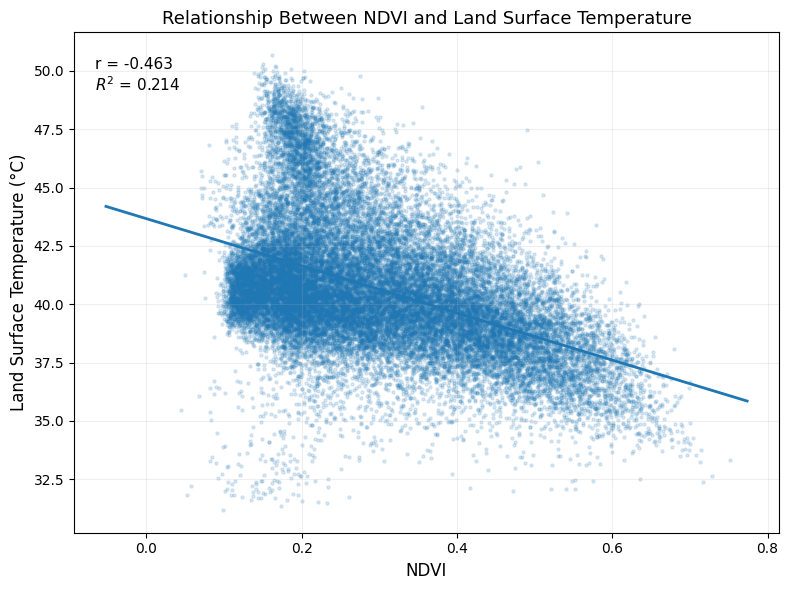


NDBI vs LST
Pearson correlation (r): 0.6452
Slope: 21.5206
Intercept: 41.4849
R-squared: 0.4163
P-value: 0.0000e+00


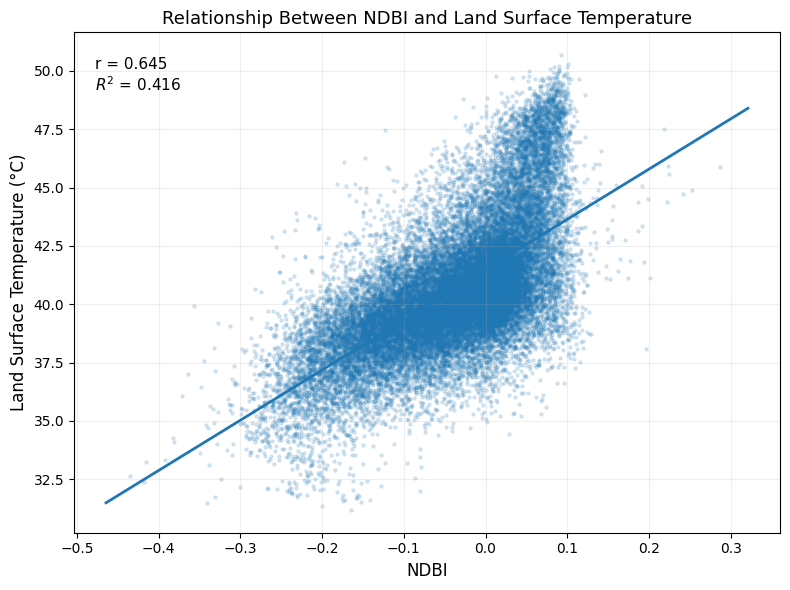


LST BY NDVI QUARTILE
                         Mean_NDVI   Mean_LST    SD_LST       N
NDVI_quartile                                                  
Q1 - Lowest vegetation    0.155076  41.770007  2.844655  478329
Q2                        0.226739  41.727788  2.873224  478329
Q3                        0.326432  40.470287  2.215058  478329
Q4 - Highest vegetation   0.479990  38.693085  1.993020  478329


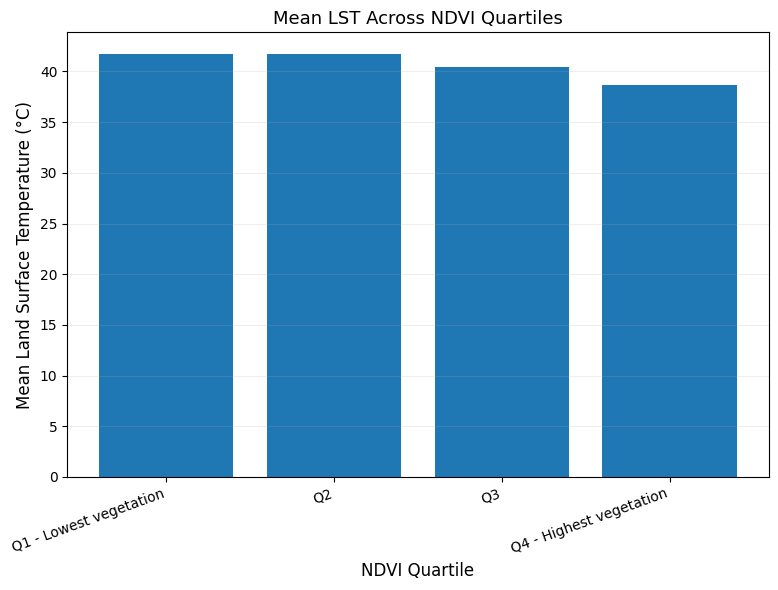


LST BY NDBI QUARTILE
                       Mean_NDBI   Mean_LST    SD_LST       N
NDBI_quartile                                                
Q1 - Lowest built-up   -0.156359  38.361614  1.986546  478329
Q2                     -0.055384  40.049910  1.821328  478329
Q3                      0.003192  41.067579  1.916958  478329
Q4 - Highest built-up   0.056203  43.182064  2.895352  478329


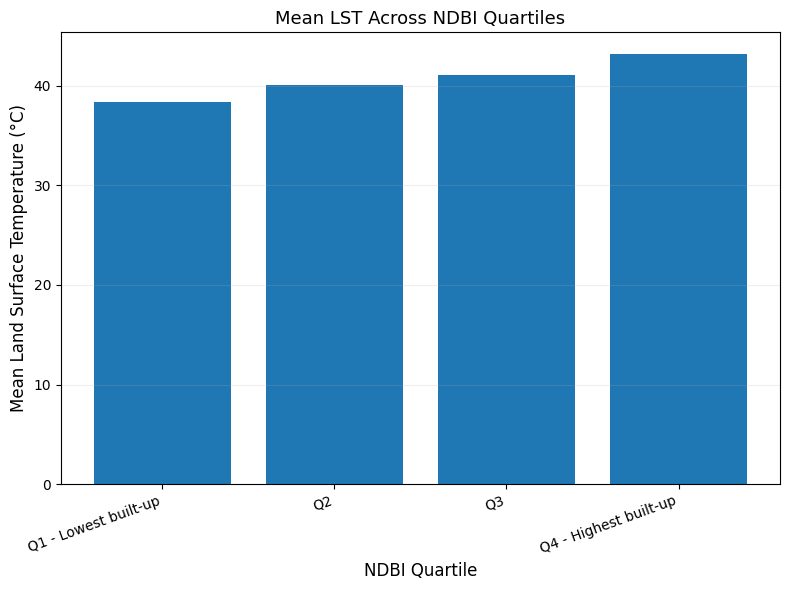


MULTIPLE LINEAR REGRESSION
                            OLS Regression Results                            
Dep. Variable:                    LST   R-squared:                       0.427
Model:                            OLS   Adj. R-squared:                  0.427
Method:                 Least Squares   F-statistic:                 7.116e+05
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        03:53:42   Log-Likelihood:            -4.1572e+06
No. Observations:             1913316   AIC:                         8.314e+06
Df Residuals:                 1913313   BIC:                         8.314e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         40.5455   

In [ ]:
# ============================================================
# DELHI URBAN HEAT ISLAND ANALYSIS
# NDVI – NDBI – LST Statistical Analysis
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import linregress
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("Libraries imported successfully.")


# ------------------------------------------------------------
# 2. LOAD VERIFIED DATASET
# ------------------------------------------------------------

file_path = 'delhi_combined_data_verified.csv'

df = pd.read_csv(file_path)

print("\nDataset loaded successfully.")
print("Shape:", df.shape)

print("\nMissing values:")
print(df.isna().sum())


# ------------------------------------------------------------
# 3. BASIC DATA CLEANING / VALIDATION
# ------------------------------------------------------------

# Keep only physically meaningful NDVI values
df = df[
    (df['NDVI'] >= -1) &
    (df['NDVI'] <= 1)
].copy()

# Remove any remaining missing/infinite values
df = df.replace([np.inf, -np.inf], np.nan).dropna()

print("\nFinal observations:", len(df))

print("\nVariable ranges:")
print(df[['NDVI', 'NDBI', 'LST']].describe())


# ------------------------------------------------------------
# 4. DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

print("\n" + "="*60)
print("DESCRIPTIVE STATISTICS")
print("="*60)

descriptive = df[['NDVI', 'NDBI', 'LST']].describe().T

descriptive = descriptive[
    ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']
]

print(descriptive)


# ------------------------------------------------------------
# 5. PEARSON CORRELATION MATRIX
# ------------------------------------------------------------

print("\n" + "="*60)
print("PEARSON CORRELATION MATRIX")
print("="*60)

corr_matrix = df[['NDVI', 'NDBI', 'LST']].corr()

print(corr_matrix)


# ------------------------------------------------------------
# 6. CORRELATION HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title(
    "Pearson Correlation Matrix: NDVI, NDBI and LST",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "Figure_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# 7. NDVI vs LST LINEAR REGRESSION
# ------------------------------------------------------------

ndvi_result = linregress(
    df['NDVI'],
    df['LST']
)

ndvi_r = ndvi_result.rvalue
ndvi_r2 = ndvi_r ** 2
ndvi_slope = ndvi_result.slope
ndvi_intercept = ndvi_result.intercept

print("\n" + "="*60)
print("NDVI vs LST")
print("="*60)

print(f"Pearson correlation (r): {ndvi_r:.4f}")
print(f"Slope: {ndvi_slope:.4f}")
print(f"Intercept: {ndvi_intercept:.4f}")
print(f"R-squared: {ndvi_r2:.4f}")
print(f"P-value: {ndvi_result.pvalue:.4e}")


# ------------------------------------------------------------
# 8. NDVI vs LST SCATTERPLOT
# ------------------------------------------------------------

# Sample points only for visualization
plot_ndvi = df.sample(
    n=min(30000, len(df)),
    random_state=42
)

x = plot_ndvi['NDVI']
y = plot_ndvi['LST']

plt.figure(figsize=(8, 6))

plt.scatter(
    x,
    y,
    s=5,
    alpha=0.15
)

# Regression line
x_line = np.linspace(
    df['NDVI'].min(),
    df['NDVI'].max(),
    200
)

y_line = (
    ndvi_intercept +
    ndvi_slope * x_line
)

plt.plot(
    x_line,
    y_line,
    linewidth=2
)

plt.xlabel("NDVI", fontsize=12)
plt.ylabel("Land Surface Temperature (°C)", fontsize=12)

plt.title(
    "Relationship Between NDVI and Land Surface Temperature",
    fontsize=13
)

plt.text(
    0.03,
    0.95,
    f"r = {ndvi_r:.3f}\n"
    f"$R^2$ = {ndvi_r2:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment='top',
    fontsize=11
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "Figure_NDVI_LST.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# 9. NDBI vs LST LINEAR REGRESSION
# ------------------------------------------------------------

ndbi_result = linregress(
    df['NDBI'],
    df['LST']
)

ndbi_r = ndbi_result.rvalue
ndbi_r2 = ndbi_r ** 2
ndbi_slope = ndbi_result.slope
ndbi_intercept = ndbi_result.intercept

print("\n" + "="*60)
print("NDBI vs LST")
print("="*60)

print(f"Pearson correlation (r): {ndbi_r:.4f}")
print(f"Slope: {ndbi_slope:.4f}")
print(f"Intercept: {ndbi_intercept:.4f}")
print(f"R-squared: {ndbi_r2:.4f}")
print(f"P-value: {ndbi_result.pvalue:.4e}")


# ------------------------------------------------------------
# 10. NDBI vs LST SCATTERPLOT
# ------------------------------------------------------------

plot_ndbi = df.sample(
    n=min(30000, len(df)),
    random_state=42
)

x = plot_ndbi['NDBI']
y = plot_ndbi['LST']

plt.figure(figsize=(8, 6))

plt.scatter(
    x,
    y,
    s=5,
    alpha=0.15
)

# Regression line
x_line = np.linspace(
    df['NDBI'].min(),
    df['NDBI'].max(),
    200
)

y_line = (
    ndbi_intercept +
    ndbi_slope * x_line
)

plt.plot(
    x_line,
    y_line,
    linewidth=2
)

plt.xlabel("NDBI", fontsize=12)
plt.ylabel("Land Surface Temperature (°C)", fontsize=12)

plt.title(
    "Relationship Between NDBI and Land Surface Temperature",
    fontsize=13
)

plt.text(
    0.03,
    0.95,
    f"r = {ndbi_r:.3f}\n"
    f"$R^2$ = {ndbi_r2:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment='top',
    fontsize=11
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "Figure_NDBI_LST.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# 11. NDVI QUARTILE ANALYSIS
# ------------------------------------------------------------

df['NDVI_quartile'] = pd.qcut(
    df['NDVI'],
    q=4,
    labels=[
        'Q1 - Lowest vegetation',
        'Q2',
        'Q3',
        'Q4 - Highest vegetation'
    ]
)

ndvi_quartile = (
    df.groupby('NDVI_quartile', observed=True)
      .agg(
          Mean_NDVI=('NDVI', 'mean'),
          Mean_LST=('LST', 'mean'),
          SD_LST=('LST', 'std'),
          N=('LST', 'count')
      )
)

print("\n" + "="*60)
print("LST BY NDVI QUARTILE")
print("="*60)

print(ndvi_quartile)


# ------------------------------------------------------------
# 12. NDVI QUARTILE PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.bar(
    ndvi_quartile.index,
    ndvi_quartile['Mean_LST']
)

plt.ylabel(
    "Mean Land Surface Temperature (°C)",
    fontsize=12
)

plt.xlabel(
    "NDVI Quartile",
    fontsize=12
)

plt.title(
    "Mean LST Across NDVI Quartiles",
    fontsize=13
)

plt.xticks(
    rotation=20,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "Figure_NDVI_Quartiles.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# 13. NDBI QUARTILE ANALYSIS
# ------------------------------------------------------------

df['NDBI_quartile'] = pd.qcut(
    df['NDBI'],
    q=4,
    labels=[
        'Q1 - Lowest built-up',
        'Q2',
        'Q3',
        'Q4 - Highest built-up'
    ]
)

ndbi_quartile = (
    df.groupby('NDBI_quartile', observed=True)
      .agg(
          Mean_NDBI=('NDBI', 'mean'),
          Mean_LST=('LST', 'mean'),
          SD_LST=('LST', 'std'),
          N=('LST', 'count')
      )
)

print("\n" + "="*60)
print("LST BY NDBI QUARTILE")
print("="*60)

print(ndbi_quartile)


# ------------------------------------------------------------
# 14. NDBI QUARTILE PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.bar(
    ndbi_quartile.index,
    ndbi_quartile['Mean_LST']
)

plt.ylabel(
    "Mean Land Surface Temperature (°C)",
    fontsize=12
)

plt.xlabel(
    "NDBI Quartile",
    fontsize=12
)

plt.title(
    "Mean LST Across NDBI Quartiles",
    fontsize=13
)

plt.xticks(
    rotation=20,
    ha='right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "Figure_NDBI_Quartiles.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# 15. MULTIPLE LINEAR REGRESSION
# ------------------------------------------------------------

X = df[['NDVI', 'NDBI']]
X = sm.add_constant(X)

y = df['LST']

model = sm.OLS(
    y,
    X
).fit()

print("\n" + "="*60)
print("MULTIPLE LINEAR REGRESSION")
print("="*60)

print(model.summary())


# ------------------------------------------------------------
# 16. VIF
# ------------------------------------------------------------

vif = pd.DataFrame()

vif['Variable'] = X.columns

vif['VIF'] = [
    variance_inflation_factor(
        X.values,
        i
    )
    for i in range(X.shape[1])
]

print("\n" + "="*60)
print("VARIANCE INFLATION FACTORS")
print("="*60)

print(vif)


# ------------------------------------------------------------
# 17. COMPACT FINAL RESULTS
# ------------------------------------------------------------

print("\n")
print("="*70)
print("FINAL RESULTS SUMMARY")
print("="*70)

print(f"Number of observations: {len(df):,}")

print("\nDescriptive statistics:")
print(f"Mean NDVI: {df['NDVI'].mean():.3f}")
print(f"Mean NDBI: {df['NDBI'].mean():.3f}")
print(f"Mean LST:  {df['LST'].mean():.2f} °C")

print("\nNDVI vs LST:")
print(f"  r = {ndvi_r:.3f}")
print(f"  R² = {ndvi_r2:.3f}")
print(f"  Slope = {ndvi_slope:.3f}")

print("\nNDBI vs LST:")
print(f"  r = {ndbi_r:.3f}")
print(f"  R² = {ndbi_r2:.3f}")
print(f"  Slope = {ndbi_slope:.3f}")

print("\nMultiple regression:")
print(f"  R² = {model.rsquared:.3f}")
print(f"  Adjusted R² = {model.rsquared_adj:.3f}")
print(f"  NDVI coefficient = {model.params['NDVI']:.3f}")
print(f"  NDBI coefficient = {model.params['NDBI']:.3f}")

print("\nAnalysis complete.")
print("Figures saved as PNG files at 300 DPI.")

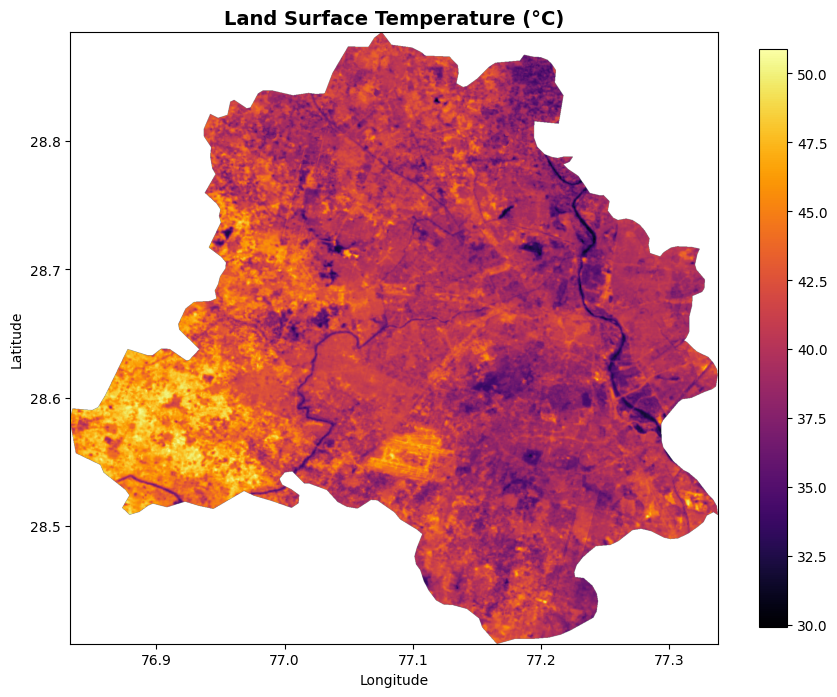

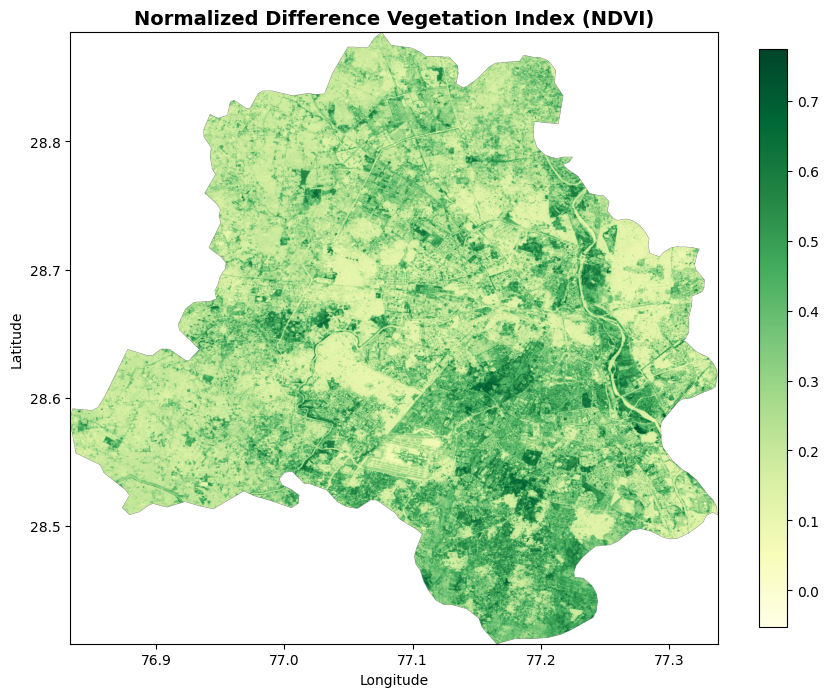

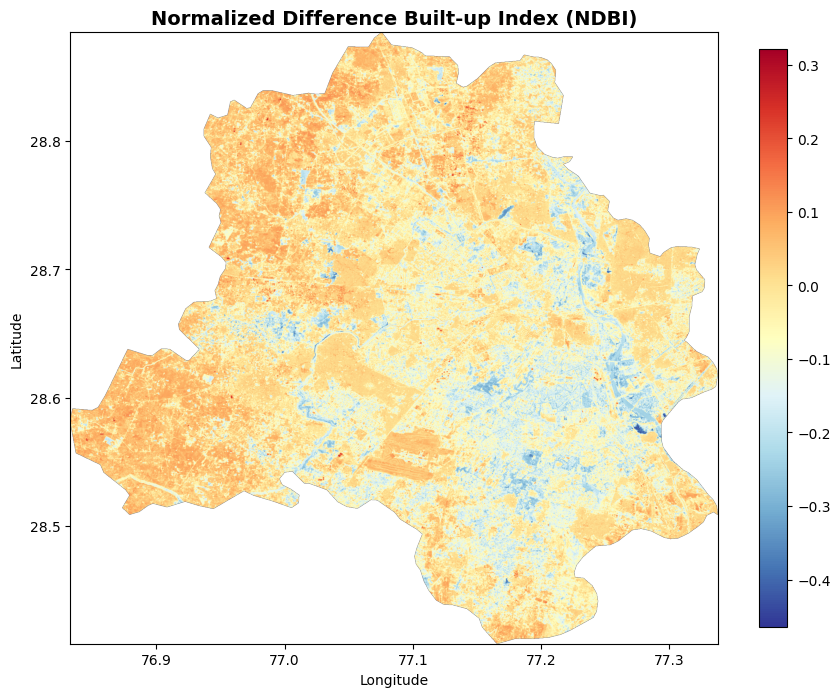

In [ ]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

files_dict = {
    "LST": "Delhi_LST_April_June_2025.tif",
    "NDVI": "Delhi_NDVI_Corrected_2025.tif",
    "NDBI": "Delhi_NDBI_April_June_2025.tif"
}

titles = {
    "LST": "Land Surface Temperature (°C)",
    "NDVI": "Normalized Difference Vegetation Index (NDVI)",
    "NDBI": "Normalized Difference Built-up Index (NDBI)"
}

cmaps = {
    "LST": "inferno",
    "NDVI": "YlGn",
    "NDBI": "RdYlBu_r"
}

for name, filename in files_dict.items():

    with rasterio.open(filename) as src:
        data = src.read(1).astype(float)
        bounds = src.bounds
        nodata = src.nodata

        if nodata is not None:
            data[data == nodata] = np.nan

        data[~np.isfinite(data)] = np.nan

        fig, ax = plt.subplots(figsize=(9, 8))

        im = ax.imshow(
            data,
            cmap=cmaps[name],
            extent=[bounds.left, bounds.right,
                    bounds.bottom, bounds.top],
            origin="upper"
        )

        ax.set_title(titles[name], fontsize=14, fontweight="bold")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

        plt.colorbar(im, ax=ax, shrink=0.75)
        plt.tight_layout()

        plt.savefig(f"{name}_Spatial_Map.png",
                    dpi=300, bbox_inches="tight")
        plt.show()